## In this Notebook we are going to analyse and prepare our data for the modeling phase.


In [40]:
import pandas as pd
from datetime import datetime
import re


In [41]:
import numpy as np
import scipy

import math
import random
import sklearn
from nltk.corpus import stopwords
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse.linalg import svds
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### Loading our data

In [42]:
interactions_df = pd.read_csv('data/cleaned_users_interactions.csv', index_col=0)
interactions_df.head(10)

,timestamp,eventType,contentId,personId,sessionId,userAgent,userRegion,userCountry,datetime,month,countryName,userCountryRegion
0,1465413032,VIEW,-3499919498720038879,-8845298781299428018,1264196770339959068,NaN,NaN,NaN,2016-06-08 21:10:32,2016-06,NaN,NaN
1,1465412560,VIEW,8890720798209849691,-1032019229384696495,3621737643587579081,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_11_2...,NY,US,2016-06-08 21:02:40,2016-06,United States,US-NY
2,1465416190,VIEW,310515487419366995,-1130272294246983140,2631864456530402479,NaN,NaN,NaN,2016-06-08 22:03:10,2016-06,NaN,NaN
3,1465413895,FOLLOW,310515487419366995,344280948527967603,-3167637573980064150,NaN,NaN,NaN,2016-06-08 21:24:55,2016-06,NaN,NaN
4,1465412290,VIEW,-7820640624231356730,-445337111692715325,5611481178424124714,NaN,NaN,NaN,2016-06-08 20:58:10,2016-06,NaN,NaN
5,1465413742,VIEW,310515487419366995,-8763398617720485024,1395789369402380392,Mozilla/5.0 (Windows NT 10.0; WOW64) AppleWebK...,MG,BR,2016-06-08 21:22:22,2016-06,Brazil,BR-MG
6,1465415950,VIEW,-8864073373672512525,3609194402293569455,1143207167886864524,NaN,NaN,NaN,2016-06-08 21:59:10,2016-06,NaN,NaN
7,1465415066,VIEW,-1492913151930215984,4254153380739593270,8743229464706506141,Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/53...,SP,BR,2016-06-08 21:44:26,2016-06,Brazil,BR-SP
8,1465413762,VIEW,310515487419366995,344280948527967603,-3167637573980064150,NaN,NaN,NaN,2016-06-08 21:22:42,2016-06,NaN,NaN
9,1465413771,VIEW,3064370296170038610,3609194402293569455,1143207167886864524,NaN,NaN,NaN,2016-06-08 21:22:51,2016-06,NaN,NaN


In [43]:
articles_df = pd.read_csv('data/shared_articles.csv')
articles_df.head(5)

,timestamp,eventType,contentId,authorPersonId,authorSessionId,authorUserAgent,authorRegion,authorCountry,contentType,url,title,text,lang
0,1459192779,CONTENT REMOVED,-6451309518266745024,4340306774493623681,8940341205206233829,NaN,NaN,NaN,HTML,http://www.nytimes.com/2016/03/28/business/dea...,"Ethereum, a Virtual Currency, Enables Transact...",All of this work is still very early. The firs...,en
1,1459193988,CONTENT SHARED,-4110354420726924665,4340306774493623681,8940341205206233829,NaN,NaN,NaN,HTML,http://www.nytimes.com/2016/03/28/business/dea...,"Ethereum, a Virtual Currency, Enables Transact...",All of this work is still very early. The firs...,en
2,1459194146,CONTENT SHARED,-7292285110016212249,4340306774493623681,8940341205206233829,NaN,NaN,NaN,HTML,http://cointelegraph.com/news/bitcoin-future-w...,Bitcoin Future: When GBPcoin of Branson Wins O...,The alarm clock wakes me at 8:00 with stream o...,en
3,1459194474,CONTENT SHARED,-6151852268067518688,3891637997717104548,-1457532940883382585,NaN,NaN,NaN,HTML,https://cloudplatform.googleblog.com/2016/03/G...,Google Data Center 360° Tour,We're excited to share the Google Data Center ...,en
4,1459194497,CONTENT SHARED,2448026894306402386,4340306774493623681,8940341205206233829,NaN,NaN,NaN,HTML,https://bitcoinmagazine.com/articles/ibm-wants...,"IBM Wants to ""Evolve the Internet"" With Blockc...",The Aite Group projects the blockchain market ...,en


### Data munging

#### 
As there are different interactions types, we associate them with a weight or strength, assuming that, for example, a comment in an article indicates a higher interest of the user on the item than a like, or than a simple view.

In [44]:
event_type_strength = {
   'VIEW': 1.0,
   'LIKE': 2.0, 
   'BOOKMARK': 2.5, 
   'FOLLOW': 3.0,
   'COMMENT CREATED': 4.0,  
}

interactions_df['eventStrength'] = interactions_df['eventType'].apply(lambda x: event_type_strength[x])

In [45]:
users_interactions_count_df = interactions_df.groupby(['personId', 'contentId']).size().groupby('personId').size()
print('# users: %d' % len(users_interactions_count_df))
users_with_enough_interactions_df = users_interactions_count_df[users_interactions_count_df >= 5].reset_index()[['personId']]
print('# users with at least 5 interactions: %d' % len(users_with_enough_interactions_df))

# users: 1894
# users with at least 5 interactions: 1138


In [46]:
print('# of interactions: %d' % len(interactions_df))
interactions_from_selected_users_df = interactions_df.merge(users_with_enough_interactions_df, 
               how = 'right',
               left_on = 'personId',
               right_on = 'personId')
print('# of interactions from users with at least 5 interactions: %d' % len(interactions_from_selected_users_df))

# of interactions: 71904
# of interactions from users with at least 5 interactions: 69466


In [47]:
import pandas as pd
import math

# Define the smoothing function
def smooth_user_preference(x):
    return math.log(1 + x, 2)

# Extract the last interaction's datetime for each (personId, contentId)
last_interactions_df = interactions_from_selected_users_df \
    .groupby(['personId', 'contentId'])['datetime'].max().reset_index()

# Aggregate eventStrength and apply smoothing
interactions_full_df = interactions_from_selected_users_df \
    .groupby(['personId', 'contentId'])['eventStrength'].sum() \
    .apply(smooth_user_preference).reset_index()

# Merge the last datetime information into interactions_full_df
interactions_full_df = interactions_full_df.merge(
    last_interactions_df,
    on=['personId', 'contentId'],
    how='left'
)

# Print the number of unique interactions
print('# of unique user/item interactions: %d' % len(interactions_full_df))

# Display the first 10 rows of the resulting dataframe
print(interactions_full_df.head(10))


# of unique user/item interactions: 38885
              personId            contentId  eventStrength  \
0 -9223121837663643404 -8949113594875411859       1.000000   
1 -9223121837663643404 -8377626164558006982       1.000000   
2 -9223121837663643404 -8208801367848627943       1.000000   
3 -9223121837663643404 -8187220755213888616       1.000000   
4 -9223121837663643404 -7423191370472335463       3.169925   
5 -9223121837663643404 -7331393944609614247       1.000000   
6 -9223121837663643404 -6872546942144599345       1.000000   
7 -9223121837663643404 -6728844082024523434       1.000000   
8 -9223121837663643404 -6590819806697898649       1.000000   
9 -9223121837663643404 -6558712014192834002       1.584963   

              datetime  
0  2016-05-05 14:42:07  
1  2016-09-15 13:25:07  
2  2016-07-28 13:51:42  
3  2016-07-06 18:51:37  
4  2016-11-17 10:56:18  
5  2016-05-17 14:00:17  
6  2017-02-21 12:50:00  
7  2017-01-24 11:06:27  
8  2017-01-24 11:06:25  
9  2016-06-03 17:42:44  


In [48]:
# Ensure the datetime column is in datetime format
interactions_full_df['datetime'] = pd.to_datetime(interactions_full_df['datetime'])

# Sort the dataset by datetime in ascending order
interactions_full_df = interactions_full_df.sort_values(by='datetime')

# Calculate the index for 80% of the data
split_index = int(len(interactions_full_df) * 0.8)

# Split the data into train (first 80%) and test (last 20%)
interactions_train_df = interactions_full_df.iloc[:split_index]
interactions_test_df = interactions_full_df.iloc[split_index:]

interactions_test_df = interactions_test_df[np.isin(interactions_test_df.personId, interactions_train_df.personId)]
interactions_train_df = interactions_train_df[np.isin(interactions_train_df.personId, interactions_test_df.personId)]
train_len = len(interactions_train_df)
test_len = len(interactions_test_df)
full_len = train_len + test_len

# Print the sizes of the train and test sets
print(f"Training set size: {len(interactions_train_df)}")
print(f"Testing set size: {len(interactions_test_df)}")

# Optionally, save the splits to separate files
interactions_train_df.to_csv('data/interactions_train.csv', index=False)
interactions_test_df.to_csv('data/interactions_test.csv', index=False)

Training set size: 28833
Testing set size: 7548


## Evaluation

In [49]:
interactions_full_indexed_df = interactions_full_df.set_index('personId')
interactions_train_indexed_df = interactions_train_df.set_index('personId')
interactions_test_indexed_df = interactions_test_df.set_index('personId')

In [50]:
def get_items_interacted(person_id, interactions_df):
    # Get the user's data and merge in the movie information.
    interacted_items = interactions_df.loc[person_id]['contentId']
    return set(interacted_items if type(interacted_items) == pd.Series else [interacted_items])

In [51]:
# Top-N accuracy metrics consts
EVAL_RANDOM_SAMPLE_NON_INTERACTED_ITEMS = 100

class ModelEvaluator:

    def get_not_interacted_items_sample(self, person_id, sample_size, seed=42):
        interacted_items = get_items_interacted(person_id, interactions_full_indexed_df)
        all_items = set(articles_df['contentId'])
        non_interacted_items = all_items - interacted_items

        random.seed(seed)
        non_interacted_items_sample = random.sample(sorted(non_interacted_items), sample_size)
        return set(non_interacted_items_sample)

    def _verify_hit_top_n(self, item_id, recommended_items, topn):        
        try:
            index = next(i for i, c in enumerate(recommended_items) if c == item_id)
        except:
            index = -1
        hit = int(index in range(0, topn))
        return hit, index

    def evaluate_model_for_user(self, model, person_id):
        # Getting the items in test set
        interacted_values_testset = interactions_test_indexed_df.loc[person_id]
        if type(interacted_values_testset['contentId']) == pd.Series:
            person_interacted_items_testset = set(interacted_values_testset['contentId'])
        else:
            person_interacted_items_testset = set([int(interacted_values_testset['contentId'])])  
        interacted_items_count_testset = len(person_interacted_items_testset) 

        # Getting a ranked recommendation list from a model for a given user
        person_recs_df = model.recommend_items(person_id, 
                                               items_to_ignore=get_items_interacted(person_id, 
                                                                                    interactions_train_indexed_df), 
                                               topn=10000000000)

        hits_at_5_count = 0
        hits_at_10_count = 0
        # For each item the user has interacted in test set
        for item_id in person_interacted_items_testset:
            # Getting a random sample (100) items the user has not interacted 
            # (to represent items that are assumed to be no relevant to the user)
            non_interacted_items_sample = self.get_not_interacted_items_sample(person_id, 
                                                                          sample_size=EVAL_RANDOM_SAMPLE_NON_INTERACTED_ITEMS, 
                                                                          seed=item_id%(2**32))

            # Combining the current interacted item with the 100 random items
            items_to_filter_recs = non_interacted_items_sample.union(set([item_id]))

            # Filtering only recommendations that are either the interacted item or from a random sample of 100 non-interacted items
            valid_recs_df = person_recs_df[person_recs_df['contentId'].isin(items_to_filter_recs)]                    
            valid_recs = valid_recs_df['contentId'].values
            # Verifying if the current interacted item is among the Top-N recommended items
            hit_at_5, index_at_5 = self._verify_hit_top_n(item_id, valid_recs, 5)
            hits_at_5_count += hit_at_5
            hit_at_10, index_at_10 = self._verify_hit_top_n(item_id, valid_recs, 10)
            hits_at_10_count += hit_at_10

        # Recall is the rate of the interacted items that are ranked among the Top-N recommended items, 
        # when mixed with a set of non-relevant items
        recall_at_5 = hits_at_5_count / float(interacted_items_count_testset)
        recall_at_10 = hits_at_10_count / float(interacted_items_count_testset)        
        person_metrics = {'hits@5_count':hits_at_5_count, 
                          'hits@10_count':hits_at_10_count, 
                          'interacted_count': interacted_items_count_testset,
                          'recall@5': recall_at_5,
                          'recall@10': recall_at_10}
        return person_metrics

    def evaluate_model(self, model):
        # print('Running evaluation for users')
        people_metrics = []
        for idx, person_id in enumerate(list(interactions_test_indexed_df.index.unique().values)):
            # if idx % 100 == 0 and idx > 0:
            #    print('%d users processed' % idx)
            person_metrics = self.evaluate_model_for_user(model, person_id)  
            person_metrics['_person_id'] = person_id
            people_metrics.append(person_metrics)
        print('%d users processed' % idx)

        detailed_results_df = pd.DataFrame(people_metrics) \
                            .sort_values('interacted_count', ascending=False)
        
        global_recall_at_5 = detailed_results_df['hits@5_count'].sum() / float(detailed_results_df['interacted_count'].sum())
        global_recall_at_10 = detailed_results_df['hits@10_count'].sum() / float(detailed_results_df['interacted_count'].sum())
        
        global_metrics = {'modelName': model.get_model_name(),
                          'recall@5': global_recall_at_5,
                          'recall@10': global_recall_at_10}    
        return global_metrics, detailed_results_df

# Instantiate the ModelEvaluator
model_evaluator = ModelEvaluator()


In [52]:
# Compute the most popular items
item_popularity_df = interactions_full_df.groupby('contentId')['eventStrength'].sum().sort_values(ascending=False).reset_index()

class PopularityRecommender:
    
    MODEL_NAME = 'Popularity'
    
    def __init__(self, popularity_df, items_df=None):
        self.popularity_df = popularity_df
        self.items_df = items_df
        
    def get_model_name(self):
        return self.MODEL_NAME
        
    def recommend_items(self, user_id, items_to_ignore=[], topn=10, verbose=False):
        # Recommend the most popular items that the user hasn't seen yet.
        recommendations_df = self.popularity_df[~self.popularity_df['contentId'].isin(items_to_ignore)] \
                               .sort_values('eventStrength', ascending=False) \
                               .head(topn)

        if verbose:
            if self.items_df is None:
                raise Exception('"items_df" is required in verbose mode')

            recommendations_df = recommendations_df.merge(self.items_df, how='left', on='contentId')[['eventStrength', 'contentId', 'title', 'url']]
        
        return recommendations_df


In [53]:
# Instantiate the PopularityRecommender
popularity_model = PopularityRecommender(item_popularity_df, articles_df)

# Test the recommender for a specific user
user_id = interactions_test_df['personId'].iloc[0]  # Example user ID from test data
recommended_items = popularity_model.recommend_items(user_id, items_to_ignore=get_items_interacted(user_id, interactions_train_indexed_df), topn=5, verbose=True)

# Display recommendations
print(recommended_items)


   eventStrength            contentId  \
0     307.733799 -4029704725707465084   
1     233.762157 -6783772548752091658   
2     228.024567  -133139342397538859   
3     197.107608 -8208801367848627943   
4     189.044680  8224860111193157980   

                                               title  \
0  Former Google career coach shares a visual tri...   
1                   Livro: Retrospectivas Divertidas   
2  Novo workaholic trabalha, pratica esportes e t...   
3  Ray Kurzweil: The world isn't getting worse - ...   
4  Psicóloga de Harvard diz que as pessoas julgam...   

                                                 url  
0  http://www.cnbc.com/2016/12/21/former-google-c...  
1  http://www.caroli.org/livro-retrospectivas-div...  
2  http://gq.globo.com/Prazeres/Poder/Carreira/no...  
3  http://www.geekwire.com/2016/ray-kurzweil-worl...  
4  http://www.jornaldoempreendedor.com.br/destaqu...  


In [54]:
popularity_global_metrics, pop_detailed_results_df = model_evaluator.evaluate_model(popularity_model)

# Now you can print global metrics and view the detailed results
print('\nGlobal metrics:\n%s' % popularity_global_metrics)
pop_detailed_results_df.head(10)


917 users processed

Global metrics:
{'modelName': 'Popularity', 'recall@5': 0.2866984631690514, 'recall@10': 0.42024377318494965}


,hits@5_count,hits@10_count,interacted_count,recall@5,recall@10,_person_id
26,29,47,220,0.131818,0.213636,3609194402293569455
77,32,45,108,0.296296,0.416667,-2979881261169775358
12,20,32,88,0.227273,0.363636,1116121227607581999
68,25,34,80,0.312500,0.425000,8698209668239173600
81,15,21,80,0.187500,0.262500,692689608292948411
8,9,15,72,0.125000,0.208333,-3596626804281480007
115,20,30,69,0.289855,0.434783,-9016528795238256703
124,17,31,64,0.265625,0.484375,2760160224512620259
100,25,35,64,0.390625,0.546875,4313045637915476309
22,19,28,59,0.322034,0.474576,-3203894957285229214


## Content-Based Filtering model


In [55]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\Mega
[nltk_data]     Pc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [56]:
#Ignoring stopwords (words with no semantics) from English and Portuguese (as we have a corpus with mixed languages)
stopwords_list = stopwords.words('english') + stopwords.words('portuguese')

#Trains a model whose vectors size is 5000, composed by the main unigrams and bigrams found in the corpus, ignoring stopwords
vectorizer = TfidfVectorizer(analyzer='word',
                     ngram_range=(1, 2),
                     min_df=0.003,
                     max_df=0.5,
                     max_features=5000,
                     stop_words=stopwords_list)

item_ids = articles_df['contentId'].tolist()
tfidf_matrix = vectorizer.fit_transform(articles_df['title'] + "" + articles_df['text'])
tfidf_feature_names = vectorizer.get_feature_names_out()
tfidf_matrix

<3122x5000 sparse matrix of type '<class 'numpy.float64'>'
	with 652107 stored elements in Compressed Sparse Row format>

### Raw TF-IDF [Model 1]¶
#### To model the user profile, we take all the item profiles the user has interacted and average them. The average is weighted by the interaction strength, in other words, the articles the user has interacted the most (eg. liked or commented) will have a higher strength in the final user profile.

In [57]:
import numpy as np
import scipy.sparse
from sklearn.preprocessing import normalize

def get_item_profile(item_id):
    idx = item_ids.index(item_id)
    item_profile = tfidf_matrix[idx:idx+1]  # This is a sparse matrix
    return item_profile

def get_item_profiles(ids):
    item_profiles_list = [get_item_profile(x) for x in ids]
    item_profiles = scipy.sparse.vstack(item_profiles_list)  # Stack sparse matrices
    return item_profiles

def build_users_profile(person_id, interactions_indexed_df):
    interactions_person_df = interactions_indexed_df.loc[person_id]
    user_item_profiles = get_item_profiles(interactions_person_df['contentId'])
    
    user_item_strengths = np.array(interactions_person_df['eventStrength']).reshape(-1, 1)
    # Weighted average of item profiles by interaction strength
    user_item_strengths_weighted_avg = np.sum(user_item_profiles.multiply(user_item_strengths), axis=0)
    user_item_strengths_weighted_avg = np.asarray(user_item_strengths_weighted_avg)  # Convert to numpy array
    user_profile_norm = normalize(user_item_strengths_weighted_avg)  # Normalize
    return user_profile_norm

def build_users_profiles():
    interactions_indexed_df = interactions_full_df[
        interactions_full_df['contentId'].isin(articles_df['contentId'])
    ].set_index('personId')
    
    user_profiles = {}
    for person_id in interactions_indexed_df.index.unique():
        user_profiles[person_id] = build_users_profile(person_id, interactions_indexed_df)
    return user_profiles


In [58]:
user_profiles = build_users_profiles()
len(user_profiles)

1138

In [59]:
class ContentBasedRecommender:
    
    MODEL_NAME = 'Content-Based'
    
    def __init__(self, items_df=None):
        self.item_ids = item_ids
        self.items_df = items_df
        
    def get_model_name(self):
        return self.MODEL_NAME
        
    def _get_similar_items_to_user_profile(self, person_id, topn=1000):
        #Computes the cosine similarity between the user profile and all item profiles
        cosine_similarities = cosine_similarity(user_profiles[person_id], tfidf_matrix)
        #Gets the top similar items
        similar_indices = cosine_similarities.argsort().flatten()[-topn:]
        #Sort the similar items by similarity
        similar_items = sorted([(item_ids[i], cosine_similarities[0,i]) for i in similar_indices], key=lambda x: -x[1])
        return similar_items
        
    def recommend_items(self, user_id, items_to_ignore=[], topn=10, verbose=False):
        similar_items = self._get_similar_items_to_user_profile(user_id)
        #Ignores items the user has already interacted
        similar_items_filtered = list(filter(lambda x: x[0] not in items_to_ignore, similar_items))
        
        recommendations_df = pd.DataFrame(similar_items_filtered, columns=['contentId', 'recStrength']) \
                                    .head(topn)

        if verbose:
            if self.items_df is None:
                raise Exception('"items_df" is required in verbose mode')

            recommendations_df = recommendations_df.merge(self.items_df, how = 'left', 
                                                          left_on = 'contentId', 
                                                          right_on = 'contentId')[['recStrength', 'contentId', 'title', 'url', 'lang']]


        return recommendations_df
    
content_based_recommender_model = ContentBasedRecommender(articles_df)

In [60]:
print('Evaluating Content-Based Filtering model...')
cb_global_metrics_1, cb_detailed_results_df_1 = model_evaluator.evaluate_model(content_based_recommender_model)
print('\nGlobal metrics:\n%s' % cb_global_metrics_1)
cb_detailed_results_df_1.sample(10)

Evaluating Content-Based Filtering model...
917 users processed

Global metrics:
{'modelName': 'Content-Based', 'recall@5': 0.48065712771595126, 'recall@10': 0.5886327503974563}


,hits@5_count,hits@10_count,interacted_count,recall@5,recall@10,_person_id
428,5,5,5,1.000000,1.000000,3617923130431400422
19,2,5,11,0.181818,0.454545,8029287010580464803
352,13,18,26,0.500000,0.692308,-7365517474830766511
346,10,19,30,0.333333,0.633333,-299809122140089170
663,0,1,1,0.000000,1.000000,-9156344805277471150
251,3,3,4,0.750000,0.750000,147389924550257400
797,4,4,4,1.000000,1.000000,7047489233409645826
162,5,5,12,0.416667,0.416667,-3535274684588209118
686,4,4,4,1.000000,1.000000,997469202936578234
349,1,1,1,1.000000,1.000000,2257339578739986222


### TF-IDF Augmentation [Model 2]
#### Now, we will try to squeeze some more information out of items (articles), not only raw TF-IDF, but also information about the lengths of titles and texts, languages, authors and when the articles was shared.

In [61]:
from sklearn.preprocessing import MinMaxScaler
minmaxScaler = MinMaxScaler()

# Get length of the title and text
articles_df['title_len'] = articles_df.title.map(len)
articles_df['text_len'] = articles_df.text.map(len)
# We use the min-amx scaler here because TF-IDF data is sparse and every value there is less than 0.5
articles_df_dummies_titletext_len = minmaxScaler.fit_transform(articles_df[['title_len', 'text_len']])
text_art_names = ['title_len', 'text_len']

# Get infornation about authors' regions
articles_df_dummies_region = pd.get_dummies(
                                articles_df.authorRegion.map(
                                        lambda x: np.nan
                                        if x not in frozenset(['SP', 'MG', 'NY', 'NJ'])
                                        else x))
region_names = articles_df_dummies_region.columns.tolist()

# Get infornation about authors' country
articles_df_dummies_country = pd.get_dummies(articles_df.authorCountry)
country_names = articles_df_dummies_country.columns.tolist()

# Get the list of authors (we consider only authors that have at least 20 articles)
authors_num_art = articles_df.authorPersonId.value_counts()
articles_df_dummies_author = pd.get_dummies(
                                articles_df.authorPersonId.map(
                                        lambda x: np.nan 
                                        if authors_num_art[x] < 20 
                                        else 'author_' + str(x)))
authors_names = ['A'+str(i) for i in range(articles_df_dummies_author.shape[1])]

# Get infornation about the day of week
day_of_week = pd.get_dummies(pd.to_datetime(articles_df.timestamp, unit='s')\
                             .dt.weekday.map(
                                {0:'Mo',1:'Tu',2:'Wd',3:'Th',4:'Fr',5:'Su',6:'Sa'}))
day_of_week_names = day_of_week.columns.tolist()

# Concatinate all the new information into one table
articles_df_dummies_all = np.hstack([articles_df_dummies_titletext_len, 
                                     articles_df_dummies_region, 
                                     articles_df_dummies_country, 
                                     articles_df_dummies_author,
                                     day_of_week])
names_all = text_art_names + region_names + country_names \
            + authors_names + day_of_week_names
print(names_all, len(names_all))

['title_len', 'text_len', 'MG', 'NJ', 'NY', 'SP', 'AU', 'BR', 'CA', 'PT', 'US', 'A0', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'A25', 'A26', 'A27', 'A28', 'A29', 'Fr', 'Mo', 'Sa', 'Su', 'Th', 'Tu', 'Wd'] 48


In [62]:
# Augmintation
from scipy.sparse import csr_matrix
tfidf_matrix = csr_matrix(scipy.sparse.hstack([0.3 * articles_df_dummies_all, tfidf_matrix]))
tfidf_matrix

<3122x5048 sparse matrix of type '<class 'numpy.float64'>'
	with 664888 stored elements in Compressed Sparse Row format>

In [63]:
user_profiles = build_users_profiles()
len(user_profiles)

1138

In [64]:
print('Evaluating Content-Based Filtering model...')
cb_global_metrics_2, cb_detailed_results_df_2 = model_evaluator.evaluate_model(content_based_recommender_model)
print('\nGlobal metrics:\n%s' % cb_global_metrics_2)
cb_detailed_results_df_2.sample(10)

Evaluating Content-Based Filtering model...
917 users processed

Global metrics:
{'modelName': 'Content-Based', 'recall@5': 0.6334128245892952, 'recall@10': 0.7533121356650768}


,hits@5_count,hits@10_count,interacted_count,recall@5,recall@10,_person_id
708,5,5,6,0.833333,0.833333,-8004014040019183404
60,4,4,6,0.666667,0.666667,-1848938642635494958
896,0,1,1,0.000000,1.000000,7866703251910305848
629,3,3,3,1.000000,1.000000,4089451522605829298
868,1,1,1,1.000000,1.000000,-5732707497022383920
14,10,16,20,0.500000,0.800000,-2820994773540913369
593,2,2,2,1.000000,1.000000,3843342266203043708
642,2,2,2,1.000000,1.000000,8236260669729422750
628,1,1,2,0.500000,0.500000,-3452896239697713851
171,16,17,36,0.444444,0.472222,3829784524040647339


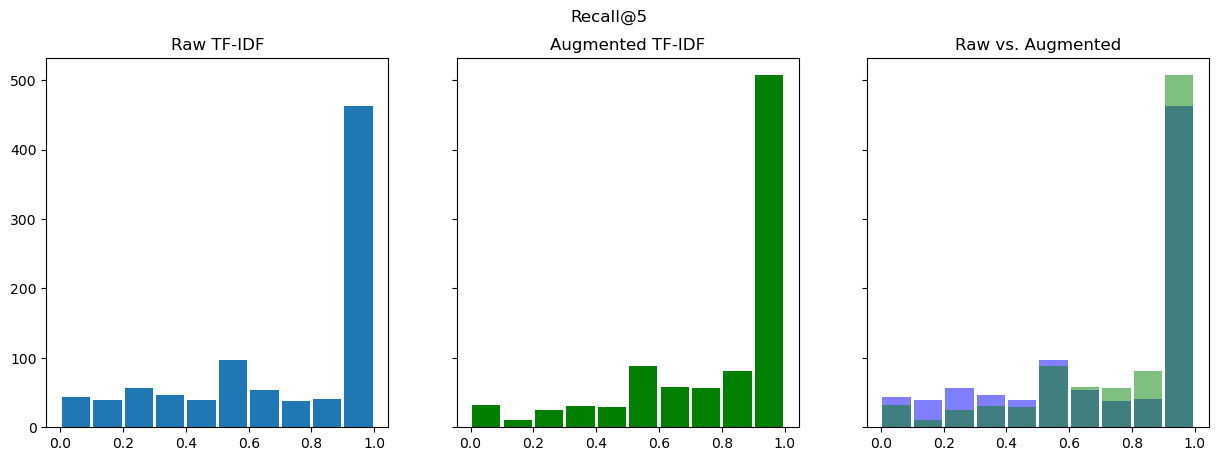

In [65]:
fig, axarr = plt.subplots(nrows=1, ncols=3, sharey=True)
fig.suptitle('Recall@5')
fig.set_figwidth(15)
# 1
axarr[0].hist(cb_detailed_results_df_1['recall@5'], rwidth=0.9);
axarr[0].set_title('Raw TF-IDF');
# 2
axarr[1].hist(cb_detailed_results_df_2['recall@5'], rwidth=0.9, color='green');
axarr[1].set_title('Augmented TF-IDF');
# 3
axarr[2].hist(cb_detailed_results_df_1['recall@5'], rwidth=0.9, color='blue', alpha=0.5);
axarr[2].hist(cb_detailed_results_df_2['recall@5'], rwidth=0.9, color='green', alpha=0.5);
axarr[2].set_title('Raw vs. Augmented');

## Collaborative Filtering model


#### Collaborative Filtering (CF) has two main implementation strategies:

#### *Memory-based: This approach uses the memory of previous users interactions to compute users similarities based on items they've interacted (user-based approach) or compute items similarities based on the users that have interacted with them (item-based approach).
#### A typical example of this approach is User Neighbourhood-based CF, in which the top-N similar users (usually computed using Pearson correlation) for a user are selected and used to recommend items those similar users liked, but the current user have not interacted yet. This approach is very simple to implement, but usually do not scale well for many users.
#### *Model-based: This approach, models are developed using different machine learning algorithms to recommend items to users. There are many model-based CF algorithms, like neural networks, bayesian networks, clustering models, and latent factor models such as Singular Value Decomposition (SVD) and, probabilistic latent semantic analysis.

### Matrix Factorization

##### Latent factor models compress user-item matrix into a low-dimensional representation in terms of latent factors. One advantage of using this approach is that instead of having a high dimensional matrix containing abundant number of missing values we will be dealing with a much smaller matrix in lower-dimensional space.
##### A reduced presentation could be utilized for either user-based or item-based neighborhood algorithms that are presented in the previous section. There are several advantages with this paradigm. It handles the sparsity of the original matrix better than memory based ones. Also comparing similarity on the resulting matrix is much more scalable especially in dealing with large sparse datasets.

##### Here we a use popular latent factor model named Singular Value Decomposition (SVD). There are other matrix factorization frameworks more specific to CF you might try, like surprise, mrec or python-recsys. We chose a SciPy implemenation of SVD because it is available on Kaggle kernels. P.s. See an example of SVD on a movies dataset in this blog post.

##### An important decision is the number of factors to factor the user-item matrix. The higher the number of factors, the more precise is the factorization in the original matrix reconstructions. Therefore, if the model is allowed to memorize too much details of the original matrix, it may not generalize well for data it was not trained on. Reducing the number of factors increases the model generalization.

In [67]:
#Creating a sparse pivot table with users in rows and items in columns
users_items_pivot_matrix_df = interactions_train_df.pivot(index='personId', 
                                                          columns='contentId', 
                                                          values='eventStrength').fillna(0)

users_items_pivot_matrix_df.head(10)

contentId,-9222795471790223670,-9216926795620865886,-9192549002213406534,-9190737901804729417,-9189659052158407108,-9184137057748005562,-9176143510534135851,-9172673334835262304,-9171475473795142532,-9166778629773133902,...,9168028029170358424,9175693555063886126,9191014301634017491,9207286802575546269,9208127165664287660,9209629151177723638,9215261273565326920,9217155070834564627,9220445660318725468,9222265156747237864
personId,,,,,,,,,,,,,,,,,,,,,
-9223121837663643404,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9207251133131336884,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9199575329909162940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9196668942822132778,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,2.321928,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9172914609055320039,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9156344805277471150,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9109785559521267180,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9060214117327732109,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
-9047547311469006438,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


In [73]:
users_items_pivot_matrix = users_items_pivot_matrix_df.to_numpy()
users_items_pivot_matrix[:10]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 2., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]])

In [74]:
users_ids = list(users_items_pivot_matrix_df.index)
users_ids[:10]

[-9223121837663643404,
 -9207251133131336884,
 -9199575329909162940,
 -9196668942822132778,
 -9172914609055320039,
 -9156344805277471150,
 -9109785559521267180,
 -9060214117327732109,
 -9047547311469006438,
 -9016528795238256703]

In [75]:
users_items_pivot_sparse_matrix = csr_matrix(users_items_pivot_matrix)
users_items_pivot_sparse_matrix

<918x2417 sparse matrix of type '<class 'numpy.float64'>'
	with 28833 stored elements in Compressed Sparse Row format>

In [76]:
#The number of factors to factor the user-item matrix.
NUMBER_OF_FACTORS_MF = 15
#Performs matrix factorization of the original user item matrix
#U, sigma, Vt = svds(users_items_pivot_matrix, k = NUMBER_OF_FACTORS_MF)
U, sigma, Vt = svds(users_items_pivot_sparse_matrix, k = NUMBER_OF_FACTORS_MF)

In [77]:
U.shape

(918, 15)

In [78]:
Vt.shape

(15, 2417)

In [79]:
sigma = np.diag(sigma)
sigma.shape

(15, 15)

In [80]:
all_user_predicted_ratings = np.dot(np.dot(U, sigma), Vt) 
all_user_predicted_ratings

array([[ 0.08683148,  0.00507532,  0.01397138, ...,  0.03526879,
         0.00489386,  0.0102518 ],
       [-0.01222133,  0.00229389,  0.00587794, ...,  0.00794394,
         0.00378322,  0.00098623],
       [ 0.0475352 ,  0.00025971, -0.01183895, ...,  0.01843024,
        -0.00114556,  0.00171041],
       ...,
       [-0.02938899,  0.00386038,  0.00341089, ..., -0.02615561,
         0.0084422 ,  0.01017471],
       [ 0.00701577,  0.00645696,  0.06785939, ...,  0.0127897 ,
         0.03095318, -0.01949399],
       [-0.03844675, -0.00055362,  0.0337737 , ..., -0.02225215,
         0.03718772,  0.00543262]])

In [81]:
all_user_predicted_ratings_norm = (all_user_predicted_ratings - all_user_predicted_ratings.min()) / (all_user_predicted_ratings.max() - all_user_predicted_ratings.min())

In [82]:
#Converting the reconstructed matrix back to a Pandas dataframe
cf_preds_df = pd.DataFrame(all_user_predicted_ratings_norm, columns = users_items_pivot_matrix_df.columns, index=users_ids).transpose()
cf_preds_df.head(10)

,-9223121837663643404,-9207251133131336884,-9199575329909162940,-9196668942822132778,-9172914609055320039,-9156344805277471150,-9109785559521267180,-9060214117327732109,-9047547311469006438,-9016528795238256703,...,9090527742744334314,9091970136990402395,9105269044962898535,9109075639526981934,9137372837662939523,9148269800512008413,9187866633451383747,9191849144618614467,9199170757466086545,9210530975708218054
contentId,,,,,,,,,,,,,,,,,,,,,
-9222795471790223670,0.183887,0.173097,0.179607,0.174344,0.175836,0.179170,0.175535,0.172680,0.173284,0.168798,...,0.172750,0.172045,0.177625,0.169752,0.174240,0.173080,0.172964,0.171227,0.175193,0.170240
-9216926795620865886,0.174981,0.174678,0.174457,0.174643,0.174685,0.174625,0.174593,0.174212,0.174283,0.176700,...,0.174406,0.174651,0.174648,0.175645,0.174482,0.177216,0.174883,0.174849,0.175132,0.174368
-9192549002213406534,0.175951,0.175069,0.173139,0.176519,0.176097,0.182865,0.170298,0.173326,0.173553,0.277376,...,0.169943,0.174341,0.176418,0.188530,0.174406,0.181880,0.176813,0.174800,0.181821,0.178108
-9190737901804729417,0.176794,0.174631,0.174694,0.174344,0.174669,0.174294,0.176410,0.174057,0.174346,0.187695,...,0.173978,0.174093,0.174976,0.174317,0.173987,0.171774,0.174418,0.175094,0.174009,0.173400
-9189659052158407108,0.174636,0.174351,0.174141,0.175310,0.175244,0.174926,0.175927,0.174846,0.175562,0.232354,...,0.176023,0.176097,0.176338,0.185545,0.174987,0.183929,0.175041,0.177370,0.176605,0.177340
-9184137057748005562,0.174890,0.174515,0.174446,0.174415,0.174575,0.174431,0.175023,0.174456,0.174498,0.175526,...,0.174653,0.174398,0.174627,0.175374,0.174317,0.173959,0.174573,0.174669,0.174773,0.174424
-9176143510534135851,0.180687,0.174323,0.176657,0.173669,0.175043,0.177049,0.180729,0.175641,0.173848,0.196767,...,0.176479,0.174536,0.176443,0.183768,0.173837,0.172923,0.174575,0.176990,0.176486,0.174580
-9172673334835262304,0.174869,0.174542,0.174300,0.174438,0.174501,0.174841,0.174478,0.174399,0.173880,0.185282,...,0.173691,0.174486,0.175050,0.175212,0.174454,0.174740,0.175260,0.174324,0.175748,0.174783
-9171475473795142532,0.176206,0.174579,0.174850,0.174438,0.174826,0.173986,0.177151,0.174291,0.174919,0.173114,...,0.174587,0.174614,0.174924,0.175637,0.174777,0.172770,0.174712,0.174479,0.174764,0.174111


In [83]:
len(cf_preds_df.columns)

918

In [84]:
class CFRecommender:
    
    MODEL_NAME = 'Collaborative Filtering'
    
    def __init__(self, cf_predictions_df, items_df=None):
        self.cf_predictions_df = cf_predictions_df
        self.items_df = items_df
        
    def get_model_name(self):
        return self.MODEL_NAME
        
    def recommend_items(self, user_id, items_to_ignore=[], topn=10, verbose=False):
        # Get and sort the user's predictions
        sorted_user_predictions = self.cf_predictions_df[user_id].sort_values(ascending=False) \
                                    .reset_index().rename(columns={user_id: 'recStrength'})

        # Recommend the highest predicted rating movies that the user hasn't seen yet.
        recommendations_df = sorted_user_predictions[~sorted_user_predictions['contentId'].isin(items_to_ignore)] \
                               .sort_values('recStrength', ascending = False) \
                               .head(topn)

        if verbose:
            if self.items_df is None:
                raise Exception('"items_df" is required in verbose mode')

            recommendations_df = recommendations_df.merge(self.items_df, how = 'left', 
                                                          left_on = 'contentId', 
                                                          right_on = 'contentId')[['recStrength', 'contentId', 'title', 'url', 'lang']]


        return recommendations_df
    
cf_recommender_model = CFRecommender(cf_preds_df, articles_df)

In [85]:
print('Evaluating Collaborative Filtering (SVD Matrix Factorization) model...')
cf_global_metrics, cf_detailed_results_df = model_evaluator.evaluate_model(cf_recommender_model)
print('\nGlobal metrics:\n%s' % cf_global_metrics)
cf_detailed_results_df.head(10)

Evaluating Collaborative Filtering (SVD Matrix Factorization) model...
917 users processed

Global metrics:
{'modelName': 'Collaborative Filtering', 'recall@5': 0.03285638579756227, 'recall@10': 0.04756226815050345}


,hits@5_count,hits@10_count,interacted_count,recall@5,recall@10,_person_id
26,2,2,220,0.009091,0.009091,3609194402293569455
77,2,4,108,0.018519,0.037037,-2979881261169775358
12,0,0,88,0.000000,0.000000,1116121227607581999
68,2,4,80,0.025000,0.050000,8698209668239173600
81,0,1,80,0.000000,0.012500,692689608292948411
8,1,1,72,0.013889,0.013889,-3596626804281480007
115,3,4,69,0.043478,0.057971,-9016528795238256703
124,8,9,64,0.125000,0.140625,2760160224512620259
100,3,7,64,0.046875,0.109375,4313045637915476309
22,4,5,59,0.067797,0.084746,-3203894957285229214


### Hybrid Recommender



##### What if we combine Collaborative Filtering and Content-Based Filtering approaches?
##### Would that provide us with more accurate recommendations?
##### In fact, hybrid methods have performed better than individual approaches in many studies and have being extensively used by researchers and practioners.
##### Let's build a simple hybridization method, as an ensemble that takes the weighted average of the normalized CF scores with the Content-Based scores, and ranking by resulting score. In this case, as the CF model is much more accurate than the CB model, the weights for the CF and CB models are 100.0 and 1.0, respectivelly.

In [86]:
class HybridRecommender:
    
    MODEL_NAME = 'Hybrid'
    
    def __init__(self, cb_rec_model, cf_rec_model, items_df, cb_ensemble_weight=1.0, cf_ensemble_weight=1.0):
        self.cb_rec_model = cb_rec_model
        self.cf_rec_model = cf_rec_model
        self.cb_ensemble_weight = cb_ensemble_weight
        self.cf_ensemble_weight = cf_ensemble_weight
        self.items_df = items_df
        
    def get_model_name(self):
        return self.MODEL_NAME
        
    def recommend_items(self, user_id, items_to_ignore=[], topn=10, verbose=False):
        #Getting the top-1000 Content-based filtering recommendations
        cb_recs_df = self.cb_rec_model.recommend_items(user_id, items_to_ignore=items_to_ignore, verbose=verbose,
                                                           topn=1000).rename(columns={'recStrength': 'recStrengthCB'})
        
        #Getting the top-1000 Collaborative filtering recommendations
        cf_recs_df = self.cf_rec_model.recommend_items(user_id, items_to_ignore=items_to_ignore, verbose=verbose, 
                                                           topn=1000).rename(columns={'recStrength': 'recStrengthCF'})
        
        #Combining the results by contentId
        recs_df = cb_recs_df.merge(cf_recs_df,
                                   how = 'outer', 
                                   left_on = 'contentId', 
                                   right_on = 'contentId').fillna(0.0)
        
        #Computing a hybrid recommendation score based on CF and CB scores
        #recs_df['recStrengthHybrid'] = recs_df['recStrengthCB'] * recs_df['recStrengthCF'] 
        recs_df['recStrengthHybrid'] = (recs_df['recStrengthCB'] * self.cb_ensemble_weight) \
                                     + (recs_df['recStrengthCF'] * self.cf_ensemble_weight)
        
        #Sorting recommendations by hybrid score
        recommendations_df = recs_df.sort_values('recStrengthHybrid', ascending=False).head(topn)

        if verbose:
            if self.items_df is None:
                raise Exception('"items_df" is required in verbose mode')

            recommendations_df = recommendations_df.merge(self.items_df, how = 'left', 
                                                          left_on = 'contentId', 
                                                          right_on = 'contentId')[['recStrengthHybrid', 'contentId', 'title', 'url', 'lang']]


        return recommendations_df
    
hybrid_recommender_model = HybridRecommender(content_based_recommender_model, cf_recommender_model, articles_df,
                                             cb_ensemble_weight=1.0, cf_ensemble_weight=100.0)

In [87]:
print('Evaluating Hybrid model...')
hybrid_global_metrics, hybrid_detailed_results_df = model_evaluator.evaluate_model(hybrid_recommender_model)
print('\nGlobal metrics:\n%s' % hybrid_global_metrics)
hybrid_detailed_results_df.head(10)

Evaluating Hybrid model...
917 users processed

Global metrics:
{'modelName': 'Hybrid', 'recall@5': 0.04862215156332803, 'recall@10': 0.06359300476947535}


,hits@5_count,hits@10_count,interacted_count,recall@5,recall@10,_person_id
26,2,3,220,0.009091,0.013636,3609194402293569455
77,2,4,108,0.018519,0.037037,-2979881261169775358
12,0,0,88,0.000000,0.000000,1116121227607581999
68,2,4,80,0.025000,0.050000,8698209668239173600
81,0,1,80,0.000000,0.012500,692689608292948411
8,1,1,72,0.013889,0.013889,-3596626804281480007
115,4,4,69,0.057971,0.057971,-9016528795238256703
124,9,10,64,0.140625,0.156250,2760160224512620259
100,3,7,64,0.046875,0.109375,4313045637915476309
22,4,5,59,0.067797,0.084746,-3203894957285229214
